# Chapitre 9 - Exercices 9.1 à 9.5

Ce notebook traite les premiers exercices du chapitre 9, consacrés à la
linéarisabilité :

- **9.1** : linéarisable ou pas ? Quatre historiques à juger (raisonnement) ;
- **9.2** : le coût d'un vérificateur de linéarisabilité, avec et sans mémoïsation
  (mini-lab) ;
- **9.3** : quorums, délais variables et réparation synchrone (mini-lab et calcul) ;
- **9.4** : placer le leader d'une base linéarisable répartie sur trois centres de
  données (calcul) ;
- **9.5** : linéarisable, sérialisable ou causal ? Et la course entre une notification
  et la réplication (raisonnement et calcul).

In [1]:
import itertools
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import consistency as cs
from ddia.consistency import Op
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
rng = np.random.default_rng(0)

## Exercice 9.1 : linéarisable ou pas ?

**Énoncé.** Un registre $x$ vaut initialement 0. Pour chacun des quatre historiques
suivants (intervalles [appel, réponse] en millisecondes), dire s'il est linéarisable ; si
oui, donner un ordre de linéarisation, sinon expliquer pourquoi aucun n'existe.

- **(a)** A : `write(1)` [0, 4] ; B : `write(2)` [1, 3] ; C : `read → 2` [5, 6] ; C : `read → 1` [7, 8].
- **(b)** A : `cas(0 → 1) ok` [0, 2] ; B : `cas(0 → 2) ok` [1, 3].
- **(c)** A : `write(1)` [0, ∞[ sans réponse (délai expiré) ; B : `read → 0` [2, 3] ; C : `read → 1` [4, 5].
- **(d)** A : `write(1)` [0, 1] ; B : `read → 0` [0,5 ; 3] ; C : `read → 1` [2 ; 2,5].

Vérifier ensuite les réponses avec `cs.check_linearizable`.

**Rappels.** Définition par points de linéarisation, lectures concurrentes d'une écriture,
opérations sans réponse (cours 1, section 2 ; section *What Makes a System Linearizable?*).

**Solution.**

- **(a) Non.** Les deux écritures sont terminées à $t = 4$, avant les deux lectures de C,
  qui sont séquentielles. Après les deux écritures, la valeur est fixée (1 ou 2 selon
  l'ordre des points) et plus personne n'écrit : deux lectures successives ne peuvent pas
  renvoyer 2 puis 1.
- **(b) Non.** Les deux CAS attendent 0 et réussissent. Quel que soit l'ordre, le second
  trouve la valeur écrite par le premier (1 ou 2), pas 0 : il devrait échouer.
- **(c) Oui.** Une écriture sans réponse a pu prendre effet à n'importe quel instant après
  son appel (ou jamais). Ordre : lecture de B (0), puis l'écriture de A, placée après le
  point de B et avant 5, puis la lecture de C (1).
- **(d) Oui, et c'est le piège.** B lit 0 alors que l'écriture de 1 est **terminée** avant
  la fin de B, et que C a même lu 1 **pendant** la lecture de B. Mais B a commencé à 0,5,
  avant la fin de l'écriture : on place par exemple le point de B à 0,55, celui de
  l'écriture à 0,7, et celui de C à 2,2 (le vérificateur choisit 0,88 pour les deux
  premiers, B passant en premier). Les lectures concurrentes ont droit à l'ancienne valeur tant que leur
  point peut précéder celui de l'écriture.

,historique,linéarisable,ordre
0,(a),False,-
1,(b),False,-
2,(c),True,B:r→0@2.15 ; A:w(1)@2.15 ; C:r→1@4.15
3,(d),True,B:r→0@0.88 ; A:w(1)@0.88 ; C:r→1@2.08


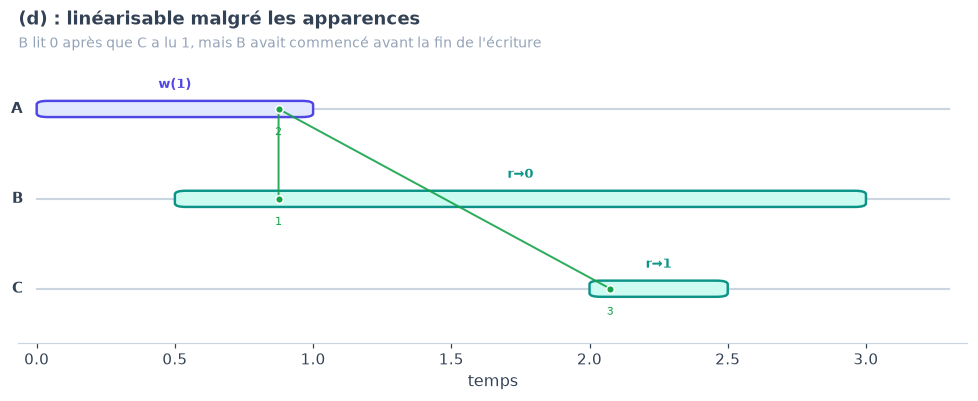

In [2]:
cas_ex = {
    "(a)": [Op("A", "write", 1, "ok", 0, 4), Op("B", "write", 2, "ok", 1, 3), Op("C", "read", None, 2, 5, 6),
            Op("C", "read", None, 1, 7, 8)],
    "(b)": [Op("A", "cas", (0, 1), True, 0, 2), Op("B", "cas", (0, 2), True, 1, 3)],
    "(c)": [Op("A", "write", 1, None, 0, done=False), Op("B", "read", None, 0, 2, 3), Op("C", "read", None, 1, 4, 5)],
    "(d)": [Op("A", "write", 1, "ok", 0, 1), Op("B", "read", None, 0, 0.5, 3), Op("C", "read", None, 1, 2, 2.5)],
}
rows = []
for k, h in cas_ex.items():
    r = cs.check_linearizable(h)
    rows.append(dict(historique=k, linéarisable=r.ok,
                     ordre=" ; ".join(f"{h[i].client}:{cs.op_label(h[i])}@{p:.2f}" for i, p in zip(r.order, r.points)) if r.ok else "-"))
display(pd.DataFrame(rows))
r = cs.check_linearizable(cas_ex["(d)"])
st = cs.plot_history(cas_ex["(d)"], title="(d) : linéarisable malgré les apparences",
                     subtitle="B lit 0 après que C a lu 1, mais B avait commencé avant la fin de l'écriture",
                     result=r, clients=["A", "B", "C"], t_max=3.3, width=9)
st.show()

Le vérificateur confirme (a) et (b) non linéarisables, (c) et (d) linéarisables. Dans (d),
l'ordre trouvé place la lecture de B **avant** l'écriture : le fait que B **réponde** tard
n'oblige pas son point à être tardif.

> **À retenir.** Juger la linéarisabilité, c'est chercher des points dans les
> intervalles. Une opération longue ou sans réponse offre beaucoup de latitude ; une
> opération **terminée** avant le début d'une autre la précède forcément.

## Exercice 9.2 : le coût d'un vérificateur de linéarisabilité

**Énoncé.** Vérifier la linéarisabilité est NP-complet en général. On veut mesurer ce que
coûte la recherche en pratique.

1. Écrire un générateur d'historiques **linéarisables** de $n$ opérations réparties sur
   $k$ clients (chaque client enchaîne ses opérations ; les durées sont aléatoires, et les
   résultats des lectures sont calculés à partir de points de linéarisation tirés au
   hasard). En faire une version **non linéarisable** en corrompant la dernière lecture.
2. Écrire une recherche **sans mémoïsation** (on essaie tous les ordres compatibles avec le
   temps réel) et comparer le nombre d'états explorés à celui de `cs.check_linearizable`.
3. Comment évolue le coût avec la concurrence (nombre de clients) ? Pourquoi la version
   non linéarisable est-elle la plus chère ?

**Rappels.** Algorithme de Wing et Gong, mémoïsation de Lowe (cours 1, section 2) ;
section *What Makes a System Linearizable?* (test de linéarisabilité par enregistrement des
requêtes et réponses).

**Solution.**

*1.* Chaque client exécute ses opérations l'une après l'autre ; on tire pour chaque
opération un intervalle, puis un point dans l'intervalle ; en rejouant les opérations dans
l'ordre des points sur un registre, on obtient les résultats des lectures : l'historique
est linéarisable par construction.

*2.* Sans mémoïsation, deux préfixes différents qui mènent au même ensemble d'opérations
placées et à la même valeur sont explorés deux fois ; avec beaucoup d'opérations
concurrentes, le nombre d'ordres croît comme une factorielle.

*3.* Une recherche qui **réussit** s'arrête au premier ordre valide ; une recherche qui
**échoue** doit prouver qu'aucun ordre n'existe, donc tout explorer : c'est le pire cas.

historiques générés linéarisables : True ; corrompus rejetés : True


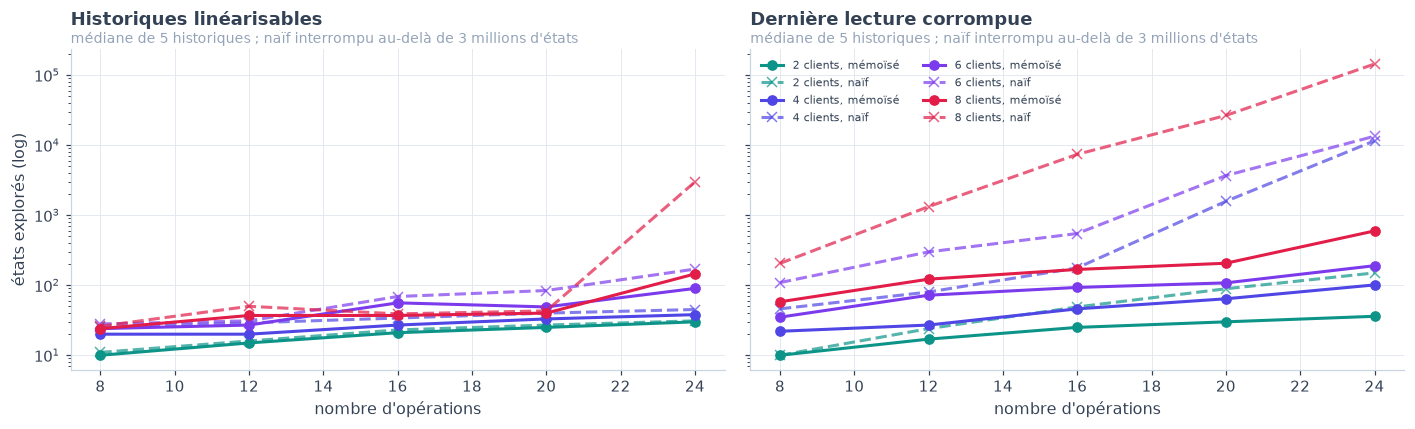

memo     naif
corrompu clients               
False    2          33       34
         4          71      320
         6         158      282
         8         312    18727
True     2          42      422
         4         108    24002
         6         358    66541
         8        1147  1348102

In [3]:
def historique_aleatoire(n, k, seed, corrompre=False):
    g = np.random.default_rng(seed)
    t = np.zeros(k)
    ops = []
    for i in range(n):
        c = int(g.integers(k))
        t0 = t[c] + g.exponential(0.3)
        t1 = t0 + g.exponential(2.0)
        t[c] = t1
        kind = "write" if g.random() < 0.4 else "read"
        ops.append(dict(client=f"c{c}", kind=kind, t0=t0, t1=t1, p=g.uniform(t0, t1), v=i + 1))
    val, hist = 0, []
    for o in sorted(ops, key=lambda o: o["p"]):
        if o["kind"] == "write":
            val = o["v"]
            hist.append(Op(o["client"], "write", o["v"], "ok", o["t0"], o["t1"]))
        else:
            hist.append(Op(o["client"], "read", None, val, o["t0"], o["t1"]))
    if corrompre:
        last = max((i for i, o in enumerate(hist) if o.kind == "read"), key=lambda i: hist[i].t_call)
        hist[last].result = -1
    return sorted(hist, key=lambda o: o.t_call)

def check_sans_memo(history, init=0, limite=3_000_000):
    ops = list(history); n = len(ops); explores = [0]
    def dfs(mask, state):
        explores[0] += 1
        if explores[0] > limite:
            raise RuntimeError
        if mask == (1 << n) - 1:
            return True
        min_ret = min(ops[i].t_return for i in range(n) if not mask >> i & 1)
        for i in range(n):
            if mask >> i & 1 or ops[i].t_call > min_ret:
                continue
            ok, s2 = cs.register_step(state, ops[i])
            if ok and dfs(mask | 1 << i, s2):
                return True
        return False
    return dfs(0, init), explores[0]

rows = []
for k in (2, 4, 6, 8):
    for n in (8, 12, 16, 20, 24):
        for corr in (False, True):
            for seed in range(5):
                h = historique_aleatoire(n, k, seed, corr)
                memo = cs.check_linearizable(h)
                try:
                    _, naive = check_sans_memo(h)
                except RuntimeError:
                    naive = np.nan
                rows.append(dict(clients=k, n=n, corrompu=corr, ok=memo.ok, memo=memo.explored, naif=naive))
X = pd.DataFrame(rows)
print("historiques générés linéarisables :", X[~X.corrompu].ok.all(), "; corrompus rejetés :", (~X[X.corrompu].ok).all())
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, corr in zip(axes, (False, True)):
    g = X[X.corrompu == corr].groupby(["clients", "n"])[["memo", "naif"]].median().reset_index()
    for k, c in zip((2, 4, 6, 8), (TEAL, INDIGO, VIOLET, ROSE)):
        s_ = g[g.clients == k]
        ax.plot(s_.n, s_.memo, "o-", color=c, label=f"{k} clients, mémoïsé")
        ax.plot(s_.n, s_.naif, "x--", color=c, alpha=0.7, label=f"{k} clients, naïf")
    ax.set_yscale("log"); ax.set_xlabel("nombre d'opérations")
    ax.set_title("Historiques linéarisables" if not corr else "Dernière lecture corrompue")
    subtitle(ax, "médiane de 5 historiques ; naïf interrompu au-delà de 3 millions d'états")
axes[0].set_ylabel("états explorés (log)")
axes[1].legend(fontsize=7.5, ncol=2, loc="upper left")
plt.tight_layout(); plt.show()
X.groupby(["corrompu", "clients"])[["memo", "naif"]].max()

Quand l'historique est linéarisable, les deux recherches trouvent vite un ordre (le premier
choix est souvent le bon), sauf quelques cas très concurrents. Quand il ne l'est pas, la
recherche naïve explose avec le nombre de clients concurrents : sa médiane croît
exponentiellement avec le nombre d'opérations, et le pire historique à 8 clients lui coûte
1,3 million d'états, contre un peu plus d'un millier pour la version mémoïsée, qui reste
dans les centaines à milliers d'états : le nombre d'**ensembles**
d'opérations placées compatibles avec le temps réel reste limité si peu d'opérations sont
concurrentes à la fois. C'est pourquoi les outils comme Knossos ou Porcupine travaillent
sur des historiques courts, découpés par clé.

> **À retenir.** Tester la linéarisabilité coûte cher dans le pire cas (un historique
> fautif oblige à tout explorer), d'autant plus que la concurrence est forte ; la
> mémoïsation des états (opérations placées, valeur) rend le test praticable.

## Exercice 9.3 : quorums, délais variables et réparation synchrone

**Énoncé.** Un registre est répliqué sur $n = 5$ nœuds sans leader.

1. Pour les configurations $(w, r) \in \{(2, 2), (3, 3), (4, 2), (5, 1)\}$, lesquelles sont
   des quorums stricts ? Pour chacune, simuler 150 exécutions (deux écrivains, deux
   lecteurs, délais log-normaux $\sigma = 0{,}8$) et mesurer la part d'historiques non
   linéarisables, en mode « Dynamo » puis en mode ABD.
2. Compter les messages échangés par lecture et par écriture dans chaque mode. Que coûte
   la linéarisabilité ?

**Rappels.** Quorums $w + r > n$ (chapitre 5), registre sur quorum non
linéarisable et algorithme ABD (cours 1, section 5 ; section *Linearizability and quorums*).

**Solution.**

*1.* $(2, 2)$ : $w + r = 4 \le 5$, pas un quorum strict (une lecture peut ne croiser aucune
réplique à jour) ; les trois autres vérifient $w + r > 5$. Mais un quorum strict ne suffit
pas à la linéarisabilité ; seule la réparation synchrone (ABD), **avec** des quorums
stricts, la garantit.

*2.* En mode Dynamo, une écriture envoie $n$ messages et en reçoit $n$ accusés (on attend
les $w$ premiers, mais les autres arrivent quand même) : $2n$ ; une lecture aussi : $2n$.
En mode ABD, chaque opération fait deux allers-retours : $4n$ messages, et deux latences
de quorum au lieu d'une.

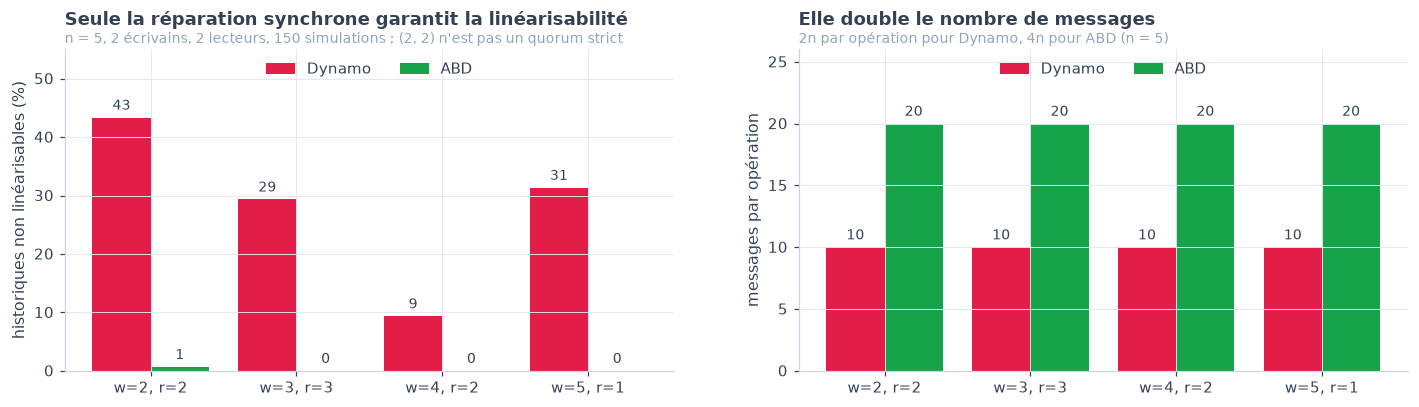

,w,r,quorum_strict,mode,non_linéarisables,messages_par_op
0,2,2,False,dynamo,0.433,10.0
1,2,2,False,abd,0.007,20.0
2,3,3,True,dynamo,0.293,10.0
3,3,3,True,abd,0.000,20.0
4,4,2,True,dynamo,0.093,10.0
5,4,2,True,abd,0.000,20.0
6,5,1,True,dynamo,0.313,10.0
7,5,1,True,abd,0.000,20.0


In [4]:
rows = []
for (w, r) in [(2, 2), (3, 3), (4, 2), (5, 1)]:
    for mode in ("dynamo", "abd"):
        bad, msgs, nops = 0, 0, 0
        for s in range(150):
            h, net = cs.run_quorum_register(n=5, w=w, r=r, mode=mode, seed=s, sigma=0.8, n_writers=2)
            bad += not cs.check_linearizable(h).ok
            msgs += len(net.trace); nops += len(h)
        rows.append(dict(w=w, r=r, quorum_strict=w + r > 5, mode=mode, non_linéarisables=bad / 150,
                         messages_par_op=msgs / nops))
Q = pd.DataFrame(rows)
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(13, 3.8))
lab = [f"w={w}, r={r}" for w, r in [(2, 2), (3, 3), (4, 2), (5, 1)]]
x = np.arange(4)
for off, mode, c in [(-0.2, "dynamo", ROSE), (0.2, "abd", GREEN)]:
    ax.bar(x + off, Q[Q["mode"] == mode].non_linéarisables * 100, width=0.4, color=c, label="Dynamo" if mode == "dynamo" else "ABD")
    ax2.bar(x + off, Q[Q["mode"] == mode].messages_par_op, width=0.4, color=c, label="Dynamo" if mode == "dynamo" else "ABD")
annotate_bars(ax, "{:.0f}"); annotate_bars(ax2, "{:.0f}")
for a in (ax, ax2):
    a.set_xticks(x, lab); a.legend(ncol=2, loc="upper center")
ax.set_ylim(0, 55); ax2.set_ylim(0, 26)
ax.set_ylabel("historiques non linéarisables (%)")
ax.set_title("Seule la réparation synchrone garantit la linéarisabilité")
subtitle(ax, "n = 5, 2 écrivains, 2 lecteurs, 150 simulations ; (2, 2) n'est pas un quorum strict")
ax2.set_ylabel("messages par opération")
ax2.set_title("Elle double le nombre de messages")
subtitle(ax2, "2n par opération pour Dynamo, 4n pour ABD (n = 5)")
plt.tight_layout(); plt.show()
Q

Résultats conformes : en mode Dynamo, toutes les configurations produisent des
historiques non linéarisables, y compris les quorums stricts ; ABD n'en produit aucun
avec un quorum strict. Avec $(2, 2)$, même ABD échoue parfois : sans recoupement des
quorums, la phase de lecture peut manquer la dernière écriture. Les messages
(environ $2n = 10$ contre $4n = 20$ par opération) confirment le calcul.

> **À retenir.** Quorum strict et réparation synchrone sont **tous deux** nécessaires à un
> registre linéarisable sans leader, au prix de deux allers-retours par opération.

## Exercice 9.4 : placer le leader d'une base linéarisable sur trois centres de données

**Énoncé.** Une base répliquée par consensus a un nœud dans chacun de trois centres de
données : Paris (P), Virginie (V) et Singapour (S). Allers-retours : P-V 80 ms, P-S 160 ms,
V-S 220 ms ; 1 ms en local. Un tiers des clients est dans chaque site. Une écriture (ou une
lecture linéarisable) d'un client passe par le leader, qui doit obtenir l'accord d'une
majorité (lui-même plus le nœud le plus proche) avant de répondre.

1. Calculer la latence vue par les clients de chaque site selon que le leader est à P, V
   ou S. Où placer le leader ?
2. Le lien entre Singapour et les deux autres sites est coupé pendant une heure. Quelle
   part des clients perd la possibilité d'écrire, selon l'emplacement du leader avant la
   coupure ?
3. Si l'on renonçait à la linéarisabilité (lectures locales sur la réplique du site),
   que gagnerait-on ? Que perdrait-on ?

**Rappels.** Coût de la linéarisabilité, CAP (cours 1, section 6 ; section *The Cost of
Linearizability*), validation par majorité (cours 5).

**Solution.**

*1.* Latence = aller-retour client → leader + aller-retour leader → nœud le plus proche.
Leader à P : la majorité est {P, V}, soit 80 ms de validation ; clients P : 1 + 80 = 81 ms ;
V : 80 + 80 = 160 ms ; S : 160 + 80 = 240 ms ; moyenne 160 ms. Leader à V : validation avec
P (80 ms) ; clients P : 160, V : 81, S : 300 ; moyenne 180 ms. Leader à S : validation avec
P (160 ms) ; P : 320, V : 380, S : 161 ; moyenne 287 ms. **Paris**, au centre, minimise la
latence moyenne (et le pire cas : 240 ms).

*2.* Singapour isolée est une minorité. Si le leader était à P ou V, la majorité {P, V}
continue : seuls les clients de S (1/3) ne peuvent plus écrire ni lire de façon
linéarisable. Si le leader était à S, il ne peut plus valider ; P et V élisent un nouveau
leader après le délai d'élection, puis continuent : 1/3 des clients privés d'écriture
pendant l'heure, plus une indisponibilité totale de quelques secondes le temps de
l'élection.

*3.* Les lectures locales coûteraient 1 ms partout au lieu de 81 à 380 ms, et resteraient
possibles à Singapour pendant la coupure ; mais elles pourraient être périmées (jusqu'au
retard de réplication, et pendant toute la coupure à S) : c'est le choix AP pour les
lectures. Les écritures, elles, restent soumises au leader.

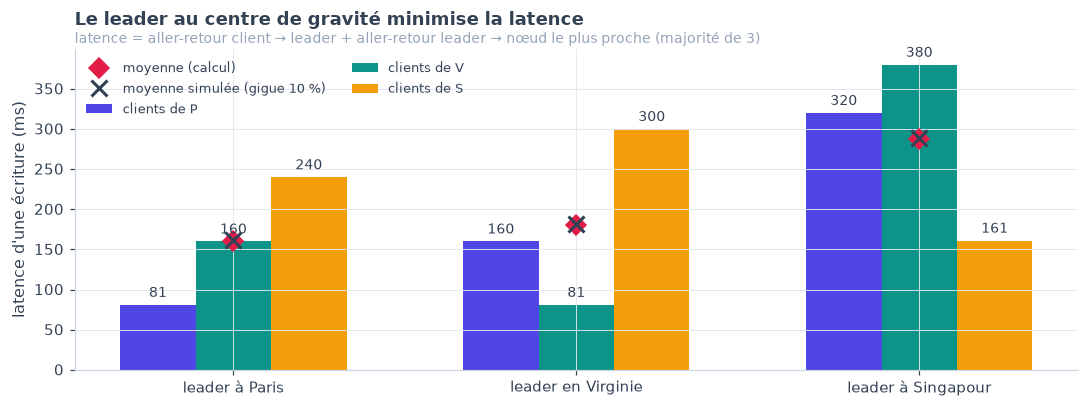

client,P,V,S,moyenne
leader,,,,
P,81,160,240,160.333
V,160,81,300,180.333
S,320,380,161,287.000


In [5]:
rtt = pd.DataFrame([[1, 80, 160], [80, 1, 220], [160, 220, 1]], index=list("PVS"), columns=list("PVS"))
rows = []
for L in "PVS":
    commit = min(rtt.loc[L, o] for o in "PVS" if o != L)
    for c in "PVS":
        rows.append(dict(leader=L, client=c, latence=rtt.loc[c, L] + commit))
T = pd.DataFrame(rows).pivot(index="leader", columns="client", values="latence").loc[list("PVS"), list("PVS")]
T["moyenne"] = T.mean(axis=1)
# vérification par simulation : allers-retours bruités (gigue log-normale de 10 %)
sim = {}
for L in "PVS":
    others = [o for o in "PVS" if o != L]
    tot = []
    for c in "PVS":
        a = rtt.loc[c, L] * rng.lognormal(0, 0.1, 20000)
        b = np.min([rtt.loc[L, o] * rng.lognormal(0, 0.1, 20000) for o in others], axis=0)
        tot.append(a + b)
    sim[L] = np.concatenate(tot)
fig, ax = plt.subplots(figsize=(10, 3.8))
x = np.arange(3)
for k, (c, col) in enumerate(zip("PVS", (INDIGO, TEAL, AMBER))):
    ax.bar(x + (k - 1) * 0.22, T[c], width=0.22, color=col, label=f"clients de {c}")
ax.plot(x, T["moyenne"], "D", color=ROSE, ms=9, label="moyenne (calcul)")
ax.plot(x, [np.mean(sim[L]) for L in "PVS"], "x", color=SLATE, ms=10, mew=2, label="moyenne simulée (gigue 10 %)")
annotate_bars(ax, "{:.0f}")
ax.set_xticks(x, ["leader à Paris", "leader en Virginie", "leader à Singapour"])
ax.set_ylabel("latence d'une écriture (ms)")
ax.set_title("Le leader au centre de gravité minimise la latence")
subtitle(ax, "latence = aller-retour client → leader + aller-retour leader → nœud le plus proche (majorité de 3)")
ax.legend(fontsize=8.5, ncol=2, loc="upper left")
plt.tight_layout(); plt.show()
T

Le calcul et la simulation concordent : 160 ms en moyenne avec le leader à Paris, contre
180 et 287 ms. La gigue augmente légèrement les moyennes simulées (l'aller-retour vers le
nœud le plus proche est le minimum de variables bruitées, ce qui le réduit un peu, mais le
reste croît).

> **À retenir.** Dans une base linéarisable multi-site, chaque écriture paie un
> aller-retour vers le leader **et** un aller-retour de validation ; on place le leader au
> centre de gravité. Une partition prive la minorité d'écritures (CP), quel que soit le
> placement.

## Exercice 9.5 : linéarisable, sérialisable ou causal ? Et la course des notifications

**Énoncé.**

1. Pour chaque scénario, dire si l'exécution respecte la sérialisabilité, la
   linéarisabilité, ou les deux (et donc la sérialisabilité stricte) :
   - (a) une base sur un seul nœud, sans transactions multi-objets, qui sert chaque
     lecture depuis l'état courant ;
   - (b) une transaction en lecture seule lit un instantané vieux de 10 secondes sur une
     réplique asynchrone, puis l'application en déduit un rapport ;
   - (c) deux médecins de garde se retirent en même temps sous un registre linéarisable
     par ligne, chacun ayant vérifié qu'un autre restait de garde (write skew) ;
   - (d) une base distribuée qui exécute les transactions en série dans l'ordre d'un
     journal partagé, et qui sert les lectures à travers ce journal.
2. Une application mobile reçoit une notification push dès qu'un message est écrit sur le
   leader, puis va lire le message sur une réplique. Le retard de réplication suit une loi
   exponentielle de moyenne 200 ms, le délai de la notification une exponentielle de
   moyenne 50 ms. Quelle est la probabilité que la lecture ne trouve pas encore le message ?
   Vérifier par simulation. Proposer une correction.

**Rappels.** Encadré *Linearizability Versus Serializability*, dépendances entre canaux
(cours 1, sections 3 et 4 ; section *Relying on Linearizability*).

**Solution.**

*1.* (a) Les deux : un seul nœud qui lit l'état courant est linéarisable, et sans
transactions multi-objets la sérialisabilité est triviale (sérialisabilité stricte).
(b) Sérialisable (l'instantané correspond à un état passé cohérent : on place la
transaction avant les écritures récentes), mais **pas** linéarisable : elle ne voit pas des
écritures terminées avant son début. (c) Linéarisable objet par objet, mais **pas**
sérialisable : le write skew implique deux objets, et la linéarisabilité ne regroupe pas
les opérations en transactions. (d) Les deux : exécution en série dans l'ordre d'un journal
partagé (sérialisable) et lectures ordonnées par le journal, en temps réel (linéarisable).

*2.* Avec $L \sim \mathcal{E}(\lambda_L)$, $\lambda_L = 1/200$ et
$N \sim \mathcal{E}(\lambda_N)$, $\lambda_N = 1/50$ indépendantes, la lecture échoue si
$N < L$ : $P(N < L) = \lambda_N / (\lambda_N + \lambda_L) = (1/50) / (1/50 + 1/200) = 0{,}8$.
Quatre fois sur cinq ! Correction : joindre à la notification la **version** (position dans
le journal de réplication) du message ; l'application lit sur une réplique **au moins à
cette version** (elle attend ou se rabat sur le leader). Le second canal transporte alors
l'information de fraîcheur, comme pour « lire ses propres écritures ».

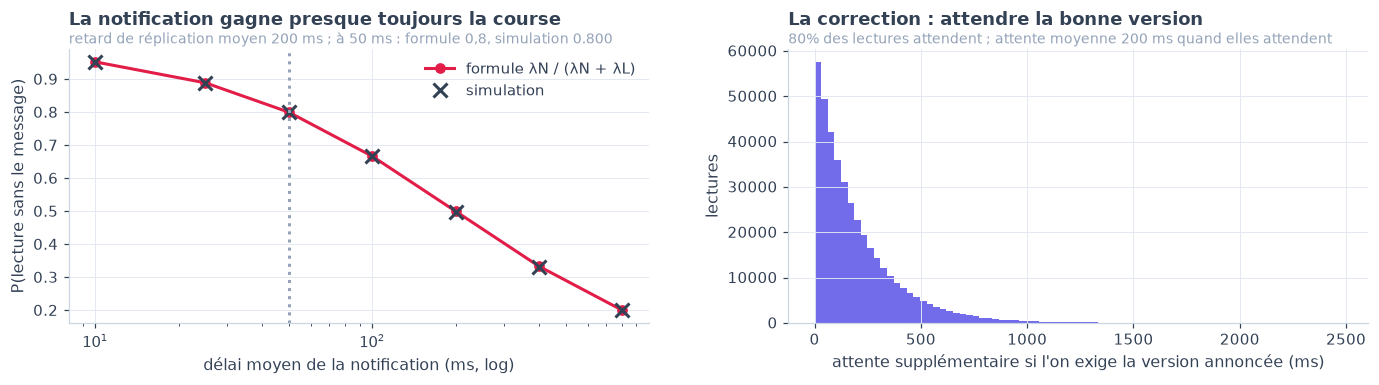

In [6]:
nsim = 500_000
L = rng.exponential(200, nsim)
Nn = rng.exponential(50, nsim)
p_sim = np.mean(Nn < L)
attente = np.maximum(L - Nn, 0)                    # attente si l'on exige la bonne version
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(13, 3.6))
moy = np.array([10, 25, 50, 100, 200, 400, 800])
ax.plot(moy, (1 / moy) / (1 / moy + 1 / 200), "o-", color=ROSE, label="formule λN / (λN + λL)")
ax.plot(moy, [np.mean(rng.exponential(m, 100_000) < rng.exponential(200, 100_000)) for m in moy], "x", color=SLATE,
        ms=9, mew=2, label="simulation")
ax.axvline(50, color=GRAY, ls=":")
ax.set_xscale("log"); ax.set_xlabel("délai moyen de la notification (ms, log)")
ax.set_ylabel("P(lecture sans le message)")
ax.set_title("La notification gagne presque toujours la course")
subtitle(ax, f"retard de réplication moyen 200 ms ; à 50 ms : formule 0,8, simulation {p_sim:.3f}")
ax.legend()
ax2.hist(attente[attente > 0], bins=80, color=INDIGO, alpha=0.8)
ax2.set_xlabel("attente supplémentaire si l'on exige la version annoncée (ms)")
ax2.set_ylabel("lectures")
ax2.set_title("La correction : attendre la bonne version")
subtitle(ax2, f"{np.mean(attente > 0):.0%} des lectures attendent ; attente moyenne {attente[attente > 0].mean():.0f} ms quand elles attendent")
plt.tight_layout(); plt.show()

La simulation confirme 0,8. Avec la correction, 80 % des lectures attendent la réplique,
en moyenne 200 ms quand elles attendent (propriété sans mémoire de l'exponentielle :
l'attente résiduelle a la même loi que le retard). On peut aussi lire directement sur le
leader, au prix de sa charge.

> **À retenir.** Sérialisabilité et linéarisabilité sont indépendantes : un instantané
> ancien est sérialisable mais pas linéarisable, un write skew sur registres linéarisables
> n'est pas sérialisable. Quand un second canal court plus vite que la réplication, il
> faut lui faire porter la version attendue.